# Embeddings and metadata: basic analysis

Load the saved crystal embeddings and metadata, inspect their shapes and sizes,
and check that they are ready for graph construction. The embedding export script
saves metadata row `i` for embedding row `i`.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

# Works when the kernel starts at the repository root or in this notebook's folder.
candidates = [
    parent / relative
    for parent in (Path.cwd(), *Path.cwd().parents)
    for relative in ("data/data", "data")
]
data_dir = next(
    (folder for folder in candidates
     if (folder / "embeddings.npy").is_file()
     and (folder / "metadata.csv").is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Could not find embeddings.npy and metadata.csv under data/.")

embeddings_path = data_dir / "embeddings.npy"
metadata_path = data_dir / "metadata.csv"
embeddings = np.load(embeddings_path, allow_pickle=False)
metadata = pd.read_csv(metadata_path)

if embeddings.ndim != 2:
    raise ValueError(f"Expected a 2D embedding matrix; got {embeddings.shape}.")
if embeddings.shape[0] != len(metadata):
    raise ValueError("Embedding and metadata row counts do not match.")

print(f"Loaded data from: {data_dir.resolve()}")

Loaded data from: C:\Users\Atharv\OneDrive\Desktop\Books\NUS Courses\CS5284_Graph_Machine_Learning\ProjectProposal\crystal-ml-proposal\data\data


## Shape and size

Each embedding row represents one crystal; columns are embedding features.
File sizes measure storage on disk; memory sizes measure the loaded data
(including metadata strings and the DataFrame index). One MiB is 1,048,576 bytes.

In [3]:
overview = pd.DataFrame([
    {
        "dataset": "embeddings",
        "shape": embeddings.shape,
        "rows": embeddings.shape[0],
        "columns": embeddings.shape[1],
        "values": embeddings.size,
        "dtype": str(embeddings.dtype),
        "file_MiB": embeddings_path.stat().st_size / 1024**2,
        "memory_MiB": embeddings.nbytes / 1024**2,
    },
    {
        "dataset": "metadata",
        "shape": metadata.shape,
        "rows": metadata.shape[0],
        "columns": metadata.shape[1],
        "values": metadata.size,
        "dtype": "mixed",
        "file_MiB": metadata_path.stat().st_size / 1024**2,
        "memory_MiB": metadata.memory_usage(index=True, deep=True).sum() / 1024**2,
    },
]).set_index("dataset")
display(overview.round(3))

print("First 5 embeddings, first 8 features:")
display(pd.DataFrame(embeddings[:5, :8]).rename_axis(index="row", columns="feature"))

,shape,rows,columns,values,dtype,file_MiB,memory_MiB
dataset,,,,,,,
embeddings,"(27136, 512)",27136,512,13893632,float32,53.000,53.00
metadata,"(27136, 9)",27136,9,244224,mixed,2.442,7.99


First 5 embeddings, first 8 features:


feature,0,1,2,3,4,5,6,7
row,,,,,,,,
0,0.176838,-0.233124,0.943807,0.278604,0.292550,0.244189,-0.394159,-0.095398
1,0.664274,0.419569,-0.420122,0.021675,-0.641636,-0.008269,-0.067970,-0.122045
2,0.247701,0.160716,-0.100733,0.354944,-0.491770,0.295882,0.007223,-0.120738
3,0.580897,-0.102405,-0.645324,-0.212167,-0.944322,-1.080245,0.506458,-0.449573
4,0.059287,-0.328596,-0.089358,-0.949137,-0.378780,-0.059136,-0.014962,1.071118


## Metadata preview and statistics

Inspect the first five crystals, column types, missing values, unique-value
counts, and descriptive statistics for numeric columns.

In [4]:
display(metadata.head())

metadata_schema = pd.DataFrame({
    "dtype": metadata.dtypes.astype(str),
    "non_null": metadata.notna().sum(),
    "missing": metadata.isna().sum(),
    "unique": metadata.nunique(),
})
display(metadata_schema)
display(metadata.describe().T)

,material_id,formation_energy_per_atom,band_gap,pretty_formula,e_above_hull,elements,spacegroup.number,num_id,chemical_system
0,mp-1221227,-1.637460,0.2133,Na3MnCoNiO6,0.043001,"['Co', 'Mn', 'Na', 'Ni', 'O']",8,0,Co-Mn-Na-Ni-O
1,mp-974729,-0.314759,0.0000,Nd(Al2Cu)4,0.000000,"['Al', 'Cu', 'Nd']",139,1,Al-Cu-Nd
2,mp-1185360,-0.193761,0.0000,LiMnIr2,0.018075,"['Ir', 'Li', 'Mn']",225,2,Ir-Li-Mn
3,mp-1188861,-0.584694,3.8556,LiCSN,0.048847,"['C', 'Li', 'N', 'S']",62,3,C-Li-N-S
4,mp-677272,-2.474759,0.4707,La2EuS4,0.000000,"['Eu', 'La', 'S']",122,4,Eu-La-S


,dtype,non_null,missing,unique
material_id,object,27136,0,27136
formation_energy_per_atom,float64,27136,0,27094
band_gap,float64,27136,0,9816
pretty_formula,object,27136,0,23540
e_above_hull,float64,27136,0,15179
elements,object,27136,0,18016
spacegroup.number,int64,27136,0,169
num_id,int64,27136,0,27136
chemical_system,object,27136,0,16549


,count,mean,std,min,25%,50%,75%,max
formation_energy_per_atom,27136.0,-1.219803,1.029393,-5.153569,-2.01325,-0.814771,-0.400797,0.079825
band_gap,27136.0,0.791848,1.417775,0.000000,0.00000,0.000000,1.142100,17.902300
e_above_hull,27136.0,0.017478,0.023265,0.000000,0.00000,0.004073,0.031026,0.079999
spacegroup.number,27136.0,122.659972,79.843672,1.000000,51.00000,139.000000,194.000000,229.000000
num_id,27136.0,13567.500000,7833.632789,0.000000,6783.75000,13567.500000,20351.250000,27135.000000


## Embedding statistics and data checks

Summarize values across the embedding matrix and the L2 length of each row.
Row counts check consistency with the export format; they do not independently
prove that the rows are in the correct order. Non-finite values or zero-length
embeddings would need attention before distance-based graph construction.

In [5]:
finite_mask = np.isfinite(embeddings)
finite_values = embeddings[finite_mask]
embedding_stats = pd.Series({
    "min": finite_values.min() if finite_values.size else np.nan,
    "max": finite_values.max() if finite_values.size else np.nan,
    "mean": finite_values.mean(dtype=np.float64) if finite_values.size else np.nan,
    "std": finite_values.std(dtype=np.float64) if finite_values.size else np.nan,
}, name="finite_embedding_values")
display(embedding_stats.to_frame())

embedding_norms = np.linalg.norm(embeddings, axis=1)
display(pd.Series(embedding_norms, name="embedding_L2_norm").describe().to_frame())

checks = pd.Series({
    "row_counts_match": embeddings.shape[0] == len(metadata),
    "non_finite_embedding_values": int((~finite_mask).sum()),
    "zero_length_embeddings": int((embedding_norms == 0).sum()),
    "missing_metadata_values": int(metadata.isna().sum().sum()),
    "duplicate_material_ids": int(metadata["material_id"].duplicated().sum()),
}, name="result")
display(checks.to_frame())

,finite_embedding_values
min,-2.129747
max,1.993900
mean,0.000503
std,0.388382


,embedding_L2_norm
count,27136.000000
mean,8.787039
std,0.135800
min,8.322221
25%,8.706676
50%,8.813362
75%,8.893038
max,9.113167


,result
row_counts_match,True
non_finite_embedding_values,0
zero_length_embeddings,0
missing_metadata_values,0
duplicate_material_ids,0


## Chemical reference sets

Following [the upstream screening implementation](../../external/Crys_JEPA/V_screen.py),
the reference set for crystal `i` contains every available crystal whose element set
is a **non-empty subset** of crystal `i`'s element set. This includes the same chemical
system and all its subsystems, regardless of stoichiometry, formation energy, or distance.
For an `A-B-C` crystal, eligible systems are `A`, `B`, `C`, `A-B`, `A-C`, `B-C`, and `A-B-C`.

Here the reference pool is the loaded `metadata`, aligned row-for-row with `embeddings`.
The query itself is excluded by default because our queries are already in that pool;
`exclude_self=False` includes it. An empty result means no *other* reference is available.
Reference membership is directional: an `A-B` crystal is eligible for an `A-B-C` query,
while the `A-B-C` crystal is not eligible for the `A-B` query.

**Usage:** `get_reference_set("mp-1221227")`, `get_reference_set(0)`, or
`get_reference_set(index=0)`. An integer is a **zero-based row position**, corresponding
to `embeddings[index]`. The returned DataFrame is indexed by those embedding row positions.
Rerun the lookup-definition cell if you replace or reorder `metadata`.

In [9]:
from functools import lru_cache
from itertools import combinations
from numbers import Integral

# Index the available reference pool once; no structures, GPU, or energy labels are needed.
required_columns = {"material_id", "chemical_system"}
if not required_columns.issubset(metadata.columns):
    raise ValueError(f"metadata must contain {sorted(required_columns)}.")
if metadata[list(required_columns)].isna().any().any():
    raise ValueError("Material IDs and chemical systems must not be missing.")
if metadata["material_id"].duplicated().any():
    raise ValueError("Material IDs must be unique for unambiguous lookup.")

_reference_systems = metadata["chemical_system"].map(
    lambda system: "-".join(sorted(set(system.split("-"))))
)
_reference_groups = _reference_systems.groupby(_reference_systems, sort=False).indices
_material_id_to_position = {
    material_id: position
    for position, material_id in enumerate(metadata["material_id"])
}


@lru_cache(maxsize=None)
def _reference_positions(chemical_system):
    """Cached pool positions for all non-empty subsystems, including the full system."""
    elements = chemical_system.split("-")
    chunks = []
    for size in range(1, len(elements) + 1):
        for subsystem in combinations(elements, size):
            key = "-".join(sorted(subsystem))
            if key in _reference_groups:
                chunks.append(_reference_groups[key])
    if not chunks:
        return np.empty(0, dtype=np.intp)
    return np.sort(np.concatenate(chunks))


def get_reference_set(material_id=None, *, index=None, exclude_self=True):
    """Return chemically eligible metadata rows for a material ID or row position.

    Supply exactly one material ID (string) or zero-based positional index (integer).
    A positional integer argument is also accepted: get_reference_set(0).
    References have an element set contained in the query's element set.
    The query is excluded by default; no energy or distance filtering is applied.
    Returned index 'embedding_index' identifies rows in the embeddings array.

    Raises KeyError for unknown IDs, IndexError for out-of-range positions,
    and TypeError/ValueError for invalid or ambiguous arguments.
    """
    if (material_id is None) == (index is None):
        raise ValueError("Supply exactly one material_id or index.")
    if not isinstance(exclude_self, (bool, np.bool_)):
        raise TypeError("exclude_self must be a boolean.")

    if material_id is not None:
        if isinstance(material_id, str):
            if material_id not in _material_id_to_position:
                raise KeyError(f"Unknown material_id: {material_id!r}")
            position = _material_id_to_position[material_id]
        elif isinstance(material_id, Integral) and not isinstance(material_id, (bool, np.bool_)):
            position = int(material_id)
        else:
            raise TypeError("material_id must be a string ID or an integer row position.")
    else:
        if not isinstance(index, Integral) or isinstance(index, (bool, np.bool_)):
            raise TypeError("index must be an integer row position.")
        position = int(index)

    if not 0 <= position < len(metadata):
        raise IndexError(f"Row position must be between 0 and {len(metadata) - 1}.")

    positions = _reference_positions(_reference_systems.iloc[position])
    if exclude_self:
        positions = positions[positions != position]
    result = metadata.iloc[positions].copy()
    result.index = pd.Index(positions, name="embedding_index")
    return result

In [11]:
anchor_index = 1  # Change this to inspect another crystal.
anchor = metadata.iloc[anchor_index]
reference_set = get_reference_set(anchor["material_id"])
# Equivalent: get_reference_set(anchor_index) or get_reference_set(index=anchor_index).
# Include the anchor: get_reference_set(anchor_index, exclude_self=False).

print(f"Anchor row: {anchor_index}; ID: {anchor['material_id']}; system: {anchor['chemical_system']}")
print(f"Reference count (self excluded): {len(reference_set):,}")
print("First 10 reference crystals; embedding_index gives the corresponding embedding rows:")
display(reference_set.head(10))

Anchor row: 1; ID: mp-974729; system: Al-Cu-Nd
Reference count (self excluded): 22
First 10 reference crystals; embedding_index gives the corresponding embedding rows:


,material_id,formation_energy_per_atom,band_gap,pretty_formula,e_above_hull,elements,spacegroup.number,num_id,chemical_system
embedding_index,,,,,,,,,
260,mp-12802,-0.189439,0.0,AlCu3,0.000000,"['Al', 'Cu']",59,260,Al-Cu
270,mp-159,0.009010,0.0,Nd,0.009010,['Nd'],225,270,Nd
3133,mp-1220197,-0.222215,0.0,NdAlCu4,0.018005,"['Al', 'Cu', 'Nd']",187,3133,Al-Cu-Nd
4421,mp-1834,-0.303266,0.0,NdAl4,0.050253,"['Nd', 'Al']",139,4421,Al-Nd
5989,mp-16513,-0.441899,0.0,NdAl3,0.000000,"['Nd', 'Al']",194,5989,Al-Nd
7604,mp-12793,-0.350258,0.0,NdAl,0.042348,"['Al', 'Nd']",221,7604,Al-Nd
8287,mp-12777,-0.164554,0.0,AlCu3,0.024885,"['Al', 'Cu']",225,8287,Al-Cu
10585,mp-998,-0.165535,0.0,Al2Cu,0.012532,"['Al', 'Cu']",140,10585,Al-Cu
12478,mp-1022721,-0.139367,0.0,AlCu,0.074061,"['Al', 'Cu']",221,12478,Al-Cu


### Reference counts across the dataset

Count the available *other reference crystals* for each anchor, rather than the number
of chemical subsystems. Every anchor contributes one observation. Empty reference sets
are retained with count zero. These counts are independent of the graph's `k` value.

Quartiles are P25 (Q1), P50 (median/Q2), and P75 (Q3). Percentile thresholds use linear
interpolation and can be fractional. Quartile-defined groups keep equal counts together,
so their sizes can differ from exactly 25% of the dataset.

In [11]:
# Crystals sharing a chemical system share the same reference pool; subtract the anchor.
_reference_count_by_system = {
    system: len(_reference_positions(system)) - 1
    for system in _reference_groups
}
reference_counts = metadata[["material_id", "pretty_formula", "chemical_system"]].copy()
reference_counts.index = pd.RangeIndex(len(metadata), name="embedding_index")
reference_counts["n_references"] = _reference_systems.map(_reference_count_by_system).to_numpy()
ref_counts = reference_counts["n_references"]

reference_summary = ref_counts.agg(["count", "mean", "std", "min", "median", "max"]).to_frame("value")
reference_summary.loc["IQR", "value"] = ref_counts.quantile(0.75) - ref_counts.quantile(0.25)
print("Reference-count summary (self excluded):")
display(reference_summary.round(3))

percentile_levels = [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 100]
reference_percentiles = pd.DataFrame({
    "percentile": [f"P{p}" for p in percentile_levels],
    "reference_count": ref_counts.quantile(np.array(percentile_levels) / 100).to_numpy(),
    "quartile": [{25: "Q1", 50: "Q2 / median", 75: "Q3"}.get(p, "") for p in percentile_levels],
}).set_index("percentile")
print("Percentiles and quartiles:")
display(reference_percentiles)

q1, q2, q3 = ref_counts.quantile([0.25, 0.5, 0.75]).to_numpy()
reference_counts["quartile_group"] = pd.Categorical(
    np.select([ref_counts <= q1, ref_counts <= q2, ref_counts <= q3],
              ["Q1", "Q2", "Q3"], default="Q4"),
    categories=["Q1", "Q2", "Q3", "Q4"], ordered=True,
)
reference_quartile_groups = (
    reference_counts.groupby("quartile_group", observed=False)["n_references"]
    .agg(n_crystals="size", min_references="min", max_references="max")
)
reference_quartile_groups["percent_of_dataset"] = (
    100 * reference_quartile_groups["n_crystals"] / len(reference_counts)
)
print("Quartile-defined groups (ties kept together):")
display(reference_quartile_groups.round(2))

reference_availability = pd.DataFrame({
    "n_crystals": {
        "No other reference": int((ref_counts == 0).sum()),
        "Fewer than 10 references": int((ref_counts < 10).sum()),
        "Fewer than 50 references": int((ref_counts < 50).sum()),
    }
})
reference_availability["percent_of_dataset"] = 100 * reference_availability["n_crystals"] / len(ref_counts)
print("Availability checks (threshold rows overlap):")
display(reference_availability.round(2))

Reference-count summary (self excluded):


,value
count,27136.000
mean,24.246
std,26.295
min,0.000
median,18.000
max,283.000
IQR,16.000


Percentiles and quartiles:


,reference_count,quartile
percentile,,
P0,0.0,
P1,2.0,
P5,5.0,
P10,6.0,
P25,11.0,Q1
P50,18.0,Q2 / median
P75,27.0,Q3
P90,45.0,
P95,65.0,


Quartile-defined groups (ties kept together):


,n_crystals,min_references,max_references,percent_of_dataset
quartile_group,,,,
Q1,7446,0,11,27.44
Q2,7094,12,18,26.14
Q3,5814,19,27,21.43
Q4,6782,28,283,24.99


Availability checks (threshold rows overlap):


,n_crystals,percent_of_dataset
Fewer than 10 references,5473,20.17
Fewer than 50 references,24794,91.37
No other reference,33,0.12


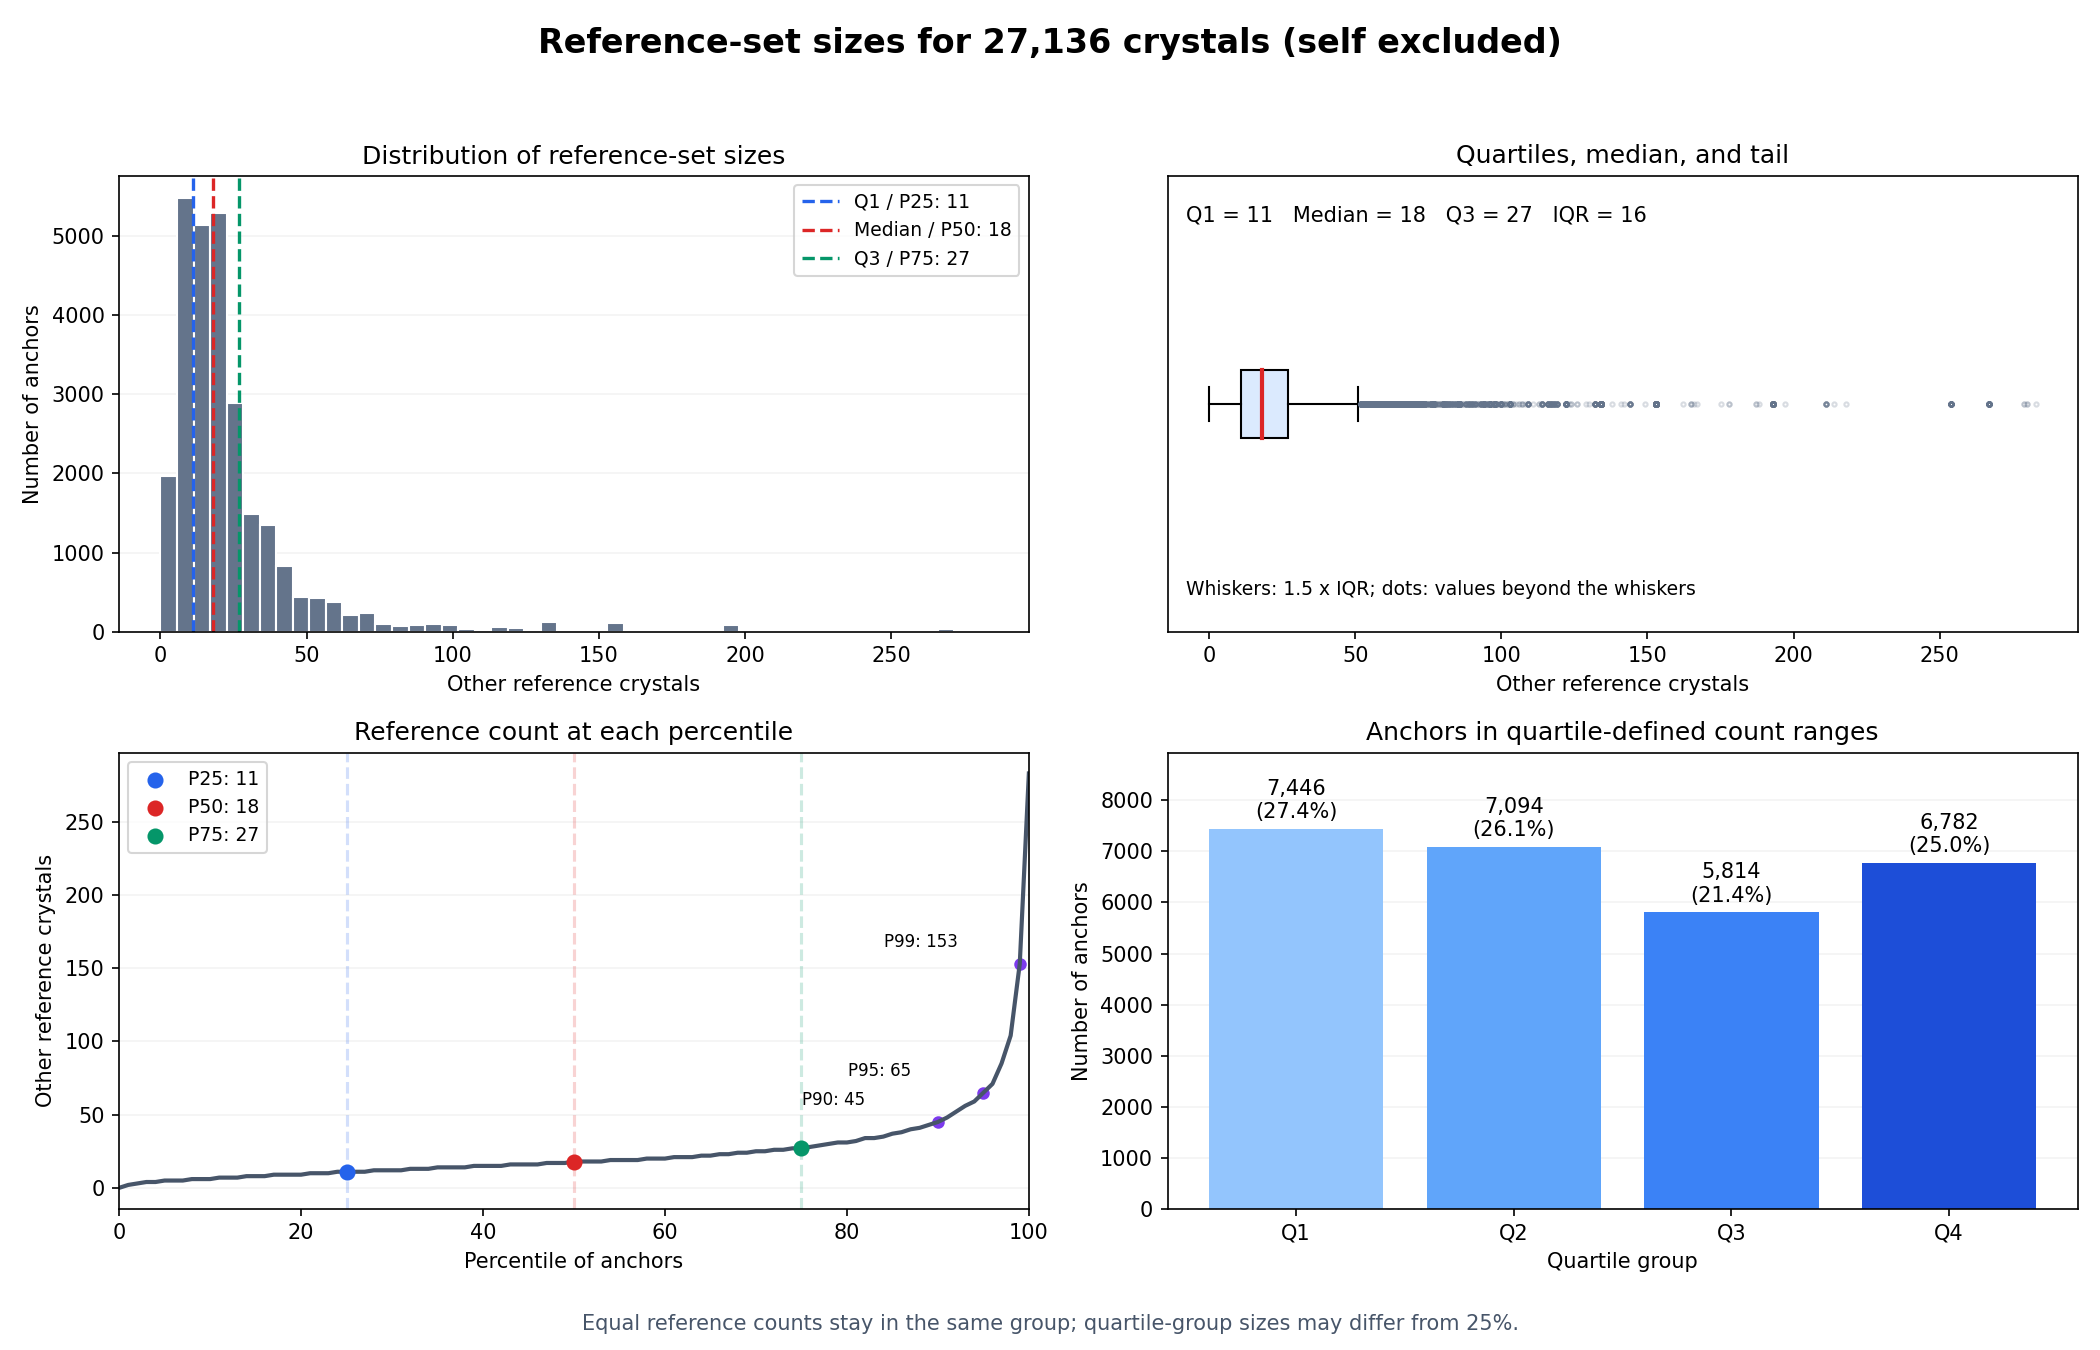

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
quartile_colors = ["#2563eb", "#dc2626", "#059669"]

ax = axes[0, 0]
ax.hist(ref_counts, bins=50, color="#64748b", edgecolor="white")
for threshold, label, color in zip([q1, q2, q3], ["Q1 / P25", "Median / P50", "Q3 / P75"], quartile_colors):
    ax.axvline(threshold, color=color, linestyle="--", linewidth=1.6,
               label=f"{label}: {threshold:g}")
ax.set(title="Distribution of reference-set sizes", xlabel="Other reference crystals", ylabel="Number of anchors")
ax.legend(fontsize=9)

ax = axes[0, 1]
ax.boxplot(ref_counts.to_numpy(), vert=False, patch_artist=True,
           boxprops={"facecolor": "#dbeafe"}, medianprops={"color": "#dc2626", "linewidth": 2},
           flierprops={"marker": ".", "markersize": 4, "alpha": 0.25, "markeredgecolor": "#64748b"})
ax.set(title="Quartiles, median, and tail", xlabel="Other reference crystals", yticks=[])
ax.text(0.02, 0.9, f"Q1 = {q1:g}   Median = {q2:g}   Q3 = {q3:g}   IQR = {q3 - q1:g}",
        transform=ax.transAxes, fontsize=10)
ax.text(0.02, 0.08, "Whiskers: 1.5 x IQR; dots: values beyond the whiskers", transform=ax.transAxes, fontsize=9)

ax = axes[1, 0]
percentile_grid = np.arange(101)
ax.plot(percentile_grid, ref_counts.quantile(percentile_grid / 100).to_numpy(), color="#475569", linewidth=2)
for percentile, threshold, color in zip([25, 50, 75], [q1, q2, q3], quartile_colors):
    ax.scatter(percentile, threshold, color=color, s=45, zorder=3,
               label=f"P{percentile}: {threshold:g}")
    ax.axvline(percentile, color=color, alpha=0.2, linestyle="--")
for percentile in [90, 95, 99]:
    threshold = ref_counts.quantile(percentile / 100)
    ax.scatter(percentile, threshold, color="#7c3aed", s=25)
    ax.annotate(f"P{percentile}: {threshold:g}", (percentile, threshold),
                xytext=(-65, 8), textcoords="offset points", fontsize=8)
ax.set(title="Reference count at each percentile", xlabel="Percentile of anchors", ylabel="Other reference crystals", xlim=(0, 100))
ax.legend(loc="upper left", fontsize=9)

ax = axes[1, 1]
labels = reference_quartile_groups.index.astype(str)
bars = ax.bar(labels, reference_quartile_groups["n_crystals"],
              color=["#93c5fd", "#60a5fa", "#3b82f6", "#1d4ed8"])
for bar, count, percentage in zip(bars, reference_quartile_groups["n_crystals"],
                                  reference_quartile_groups["percent_of_dataset"]):
    ax.annotate(f"{count:,}\n({percentage:.1f}%)", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 5), textcoords="offset points", ha="center", fontsize=10)
ax.set(title="Anchors in quartile-defined count ranges", xlabel="Quartile group", ylabel="Number of anchors")
ax.set_ylim(0, reference_quartile_groups["n_crystals"].max() * 1.2)

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
fig.suptitle(f"Reference-set sizes for {len(ref_counts):,} crystals (self excluded)", fontsize=16, fontweight="bold")
fig.text(0.5, 0.015, "Equal reference counts stay in the same group; quartile-group sizes may differ from 25%.",
         ha="center", fontsize=10, color="#475569")
fig.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

## Construct a Gaussian-weighted Euclidean k-NN graph

`build_knn_graph(embeddings, k)` returns a SciPy CSR adjacency matrix `W`.
It centers each feature, computes all pairwise Euclidean distances in chunks,
sorts each row, and selects the first `k` neighbors after excluding the point itself.
Centering preserves Euclidean distances; no feature scaling or row normalization is applied.

For selected directed edges, the Gaussian weight is
$W_{ij} = \exp(-d_{ij}^2 / (2\sigma^2))$; all other entries are zero.
By default, `sigma` is the median of the strictly positive selected neighbor distances
(or 1 if all are zero). Pass `sigma=` to choose a fixed bandwidth.
Finally, $W_{ij} \leftarrow \max(W_{ij}, W_{ji})$ makes the graph undirected,
using the sparse comparison and multiplication technique below. A one-way edge
keeps its full weight in both directions; mutual edges use the larger weight.
The symmetric graph can have more than `k` neighbors per node and has no self-loops.

The full distance matrix for 27,136 points would use about 5.49 GiB in float64,
before sorting. [Scikit-learn's chunked pairwise distances](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise_distances_chunked.html)
compute the same distances in blocks. `working_memory` controls the target distance-block
size in MiB, not total process memory; sorting needs additional space. Computation is
still quadratic in the number of points, and each distance row is fully sorted.
Dependencies: `numpy`, `pandas`, `scipy`, and `scikit-learn`.

In [6]:
from numbers import Integral, Real

from scipy.sparse import csr_matrix
from sklearn.metrics import pairwise_distances_chunked


def build_knn_graph(embeddings, k, *, sigma=None, working_memory=64):
    """Return a symmetric, Gaussian-weighted Euclidean k-NN graph as CSR.

    Parameters
    ----------
    embeddings : array-like of shape (n_samples, n_features)
        Finite real-valued embeddings. Input values and row order are preserved.
    k : int
        Neighbors selected per point before symmetrization, 1 <= k < n_samples.
    sigma : float or None
        Positive Gaussian bandwidth. None uses the median positive k-NN distance,
        falling back to 1.0 when every selected distance is zero.
    working_memory : float
        Positive target distance-chunk size in MiB (excludes sorting overhead).

    Returns
    -------
    W : scipy.sparse.csr_matrix of shape (n_samples, n_samples)
        Elementwise max(A, A.T), where A contains directed Gaussian k-NN weights.
        The diagonal is zero; row i corresponds to input embedding row i.
        Equal-distance ties are resolved by input row index.
    """
    X = np.asarray(embeddings)
    if X.ndim != 2 or X.shape[0] < 2 or X.shape[1] == 0:
        raise ValueError("embeddings must be 2D with at least 2 rows and 1 feature.")
    if X.dtype.kind not in "iuf" or not np.isfinite(X).all():
        raise ValueError("embeddings must contain only finite real numeric values.")
    n_samples = X.shape[0]
    if isinstance(k, (bool, np.bool_)) or not isinstance(k, Integral) or not 1 <= k < n_samples:
        raise ValueError("k must be an integer with 1 <= k < n_samples.")
    if sigma is not None and (
        not isinstance(sigma, Real) or not np.isfinite(sigma) or sigma <= 0
    ):
        raise ValueError("sigma must be a finite positive number or None.")
    if not isinstance(working_memory, Real) or not np.isfinite(working_memory) or working_memory <= 0:
        raise ValueError("working_memory must be a finite positive number of MiB.")

    # 1. Center each feature using a copy, leaving the original embeddings intact.
    X = X.astype(np.float64, copy=True)
    X -= X.mean(axis=0, keepdims=True)

    neighbor_indices = np.empty((n_samples, k), dtype=np.intp)
    neighbor_distances = np.empty((n_samples, k), dtype=np.float64)

    # 2-4. Compute pairwise distances, sort each row, and retain k non-self neighbors.
    start = 0
    for D in pairwise_distances_chunked(
        X, metric="euclidean", working_memory=working_memory
    ):
        stop = start + D.shape[0]
        local_rows = np.arange(D.shape[0])
        D[local_rows, np.arange(start, stop)] = np.inf
        # Stable sorting breaks ties by column index, including duplicate points.
        nearest = np.argsort(D, axis=1, kind="stable")[:, :k]
        neighbor_indices[start:stop] = nearest
        neighbor_distances[start:stop] = np.take_along_axis(D, nearest, axis=1)
        start = stop

    # 5. Gaussian weights on the selected edges only.
    if sigma is None:
        positive_distances = neighbor_distances[neighbor_distances > 0]
        sigma = float(np.median(positive_distances)) if positive_distances.size else 1.0
    with np.errstate(over="ignore", under="ignore"):
        weights = np.exp(-0.5 * (neighbor_distances / sigma) ** 2)

    # 6. Construct sparse adjacency directly, without allocating a dense W.
    rows = np.repeat(np.arange(n_samples), k)
    W = csr_matrix(
        (weights.ravel(), (rows, neighbor_indices.ravel())),
        shape=(n_samples, n_samples),
    )

    # 7. Make W symmetric by keeping the larger weight in each direction.
    bigger = W.T > W
    W = W - W.multiply(bigger) + W.T.multiply(bigger)
    W = W.tocsr()
    W.eliminate_zeros()
    W.sort_indices()
    return W

In [7]:
from time import perf_counter

from scipy.sparse.csgraph import connected_components

k = 10  # Change k here and rerun to construct another graph.
started = perf_counter()
W = build_knn_graph(embeddings, k)
elapsed = perf_counter() - started

degree = np.diff(W.indptr)
n_components, component_labels = connected_components(W, directed=False)
graph_summary = pd.Series({
    "k_before_symmetrization": k,
    "adjacency_shape": W.shape,
    "format": W.format,
    "stored_nonzero_weights": W.nnz,
    "undirected_edges": W.nnz // 2,
    "density": W.nnz / (W.shape[0] * W.shape[1]),
    "sparse_memory_MiB": (W.data.nbytes + W.indices.nbytes + W.indptr.nbytes) / 1024**2,
    "min_degree": degree.min(),
    "mean_degree": degree.mean(),
    "max_degree": degree.max(),
    "connected_components": n_components,
    "self_loops": np.count_nonzero(W.diagonal()),
    "symmetric": (W != W.T).nnz == 0,
    "build_seconds": elapsed,
}, name="value")
display(graph_summary.to_frame())
print("First 5 x 5 adjacency entries (small dense preview only):")
display(pd.DataFrame(W[:5, :5].toarray()))

,value
k_before_symmetrization,10
adjacency_shape,"(27136, 27136)"
format,csr
stored_nonzero_weights,402272
undirected_edges,201136
density,0.000546
sparse_memory_MiB,4.707157
min_degree,10
mean_degree,14.824292
max_degree,35


First 5 x 5 adjacency entries (small dense preview only):


,0,1,2,3,4
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0


In [8]:
W.shape

(27136, 27136)

## Sweep k using cached exact nearest neighbors

Sweep `k = [5, 10, 15, 20, 30, 50, 75, 100]` using a single exact Euclidean
nearest-neighbor calculation. The cache stores the nearest 100 **other** crystals
and their distances for each row; no dense all-pairs matrix is stored on disk.
All smaller neighborhoods are prefixes of the same sorted lists. Centering and
distance-tie ordering match `build_knn_graph`.

The cache under `data/data/cache/` is checked against the embedding contents,
shape, dtype, and algorithm version. Changed or reordered embeddings invalidate it.
Set `force_recompute=True` to rebuild it explicitly.
After running the data-loading and reference-function cells, this sweep section can run
directly; it does not require rerunning the earlier standalone k=10 graph construction.

We report two views:
- **Directed top-k:** exactly k neighbors selected by each anchor.
- **Symmetric union:** neighbors after your sparse maximum-weight symmetrization,
  including incoming edges. Degrees can exceed k. A binary adjacency is sufficient
  here because the requested metrics are unweighted and depend on edge membership.

Every energy difference is **absolute**, `abs(E_anchor - E_neighbor)`, in eV/atom.
Each node gets a mean and median gap. The dataset summary reports the mean of node
means and the median of node medians; a separate pooled pair median is also provided.
Reference fraction is `reference neighbors / all neighbors`, including zero-reference
anchors with fraction zero. The additional reference-recall diagnostic measures
`reference neighbors / available references`; its mean excludes empty reference sets.
Means give every anchor equal weight, including in the symmetric graph.

In [13]:
import hashlib
import json
from numbers import Integral, Real
from pathlib import Path
from time import perf_counter, sleep

from sklearn.metrics import pairwise_distances_chunked


def cache_nearest_neighbors(embeddings, max_k, cache_path, *, working_memory=64, force_recompute=False):
    """Load or compute exact sorted Euclidean neighbors, excluding self.

    Returns (neighbor_indices, neighbor_distances), each with shape (N, max_k).
    Computation is chunked; the persistent NPZ cache is keyed to ordered embedding
    contents and the distance/sorting method. A cache with more neighbors can be reused.
    """
    X = np.asarray(embeddings)
    if X.ndim != 2 or X.shape[0] < 2 or X.shape[1] == 0:
        raise ValueError("embeddings must be 2D with at least 2 rows and 1 feature.")
    if X.dtype.kind not in "iuf" or not np.isfinite(X).all():
        raise ValueError("embeddings must contain finite real numeric values.")
    n = X.shape[0]
    if isinstance(max_k, (bool, np.bool_)) or not isinstance(max_k, Integral) or not 1 <= max_k < n:
        raise ValueError("max_k must be an integer with 1 <= max_k < n_samples.")
    if not isinstance(working_memory, Real) or not np.isfinite(working_memory) or working_memory <= 0:
        raise ValueError("working_memory must be finite and positive (MiB).")

    contiguous = np.ascontiguousarray(X)
    signature = {
        "embedding_sha256": hashlib.sha256(memoryview(contiguous).cast("B")).hexdigest(),
        "shape": list(X.shape),
        "dtype": X.dtype.str,
        "algorithm": "centered-float64-euclidean-stable-row-index-ties-v1",
    }
    cache_path = Path(cache_path)
    if cache_path.is_file() and not force_recompute:
        try:
            with np.load(cache_path, allow_pickle=False) as saved:
                saved_signature = json.loads(saved["signature"].item())
                indices = saved["neighbor_indices"]
                distances = saved["neighbor_distances"]
            valid = (
                saved_signature == signature
                and indices.ndim == 2 and indices.shape[0] == n and indices.shape[1] >= max_k
                and indices.shape == distances.shape and indices.dtype.kind in "iu"
                and np.isfinite(distances).all() and (distances >= 0).all()
                and (indices >= 0).all() and (indices < n).all()
                and not (indices == np.arange(n)[:, None]).any()
                and (np.diff(distances, axis=1) >= 0).all()
            )
            if valid:
                print(f"Loaded cached top-{indices.shape[1]} neighbors: {cache_path}")
                return indices[:, :max_k].copy(), distances[:, :max_k].copy()
            print("Cache does not match the requested data/configuration; rebuilding.")
        except (OSError, ValueError, KeyError):
            print("Cache could not be read; rebuilding.")

    centered = X.astype(np.float64, copy=True)
    centered -= centered.mean(axis=0, keepdims=True)
    index_dtype = np.int32 if n <= np.iinfo(np.int32).max else np.int64
    indices = np.empty((n, max_k), dtype=index_dtype)
    distances = np.empty((n, max_k), dtype=np.float64)
    started = perf_counter()
    start = 0
    next_progress = 0.1
    print(f"Computing exact top-{max_k} neighbors for {n:,} crystals...", flush=True)
    for D in pairwise_distances_chunked(centered, metric="euclidean", working_memory=working_memory):
        stop = start + len(D)
        D[np.arange(len(D)), np.arange(start, stop)] = np.inf
        nearest = np.argsort(D, axis=1, kind="stable")[:, :max_k].copy()
        indices[start:stop] = nearest
        distances[start:stop] = np.take_along_axis(D, nearest, axis=1)
        start = stop
        if stop / n >= next_progress or stop == n:
            print(f"  {stop:,}/{n:,} rows ({stop / n:.0%})", flush=True)
            next_progress += 0.1

    cache_path.parent.mkdir(parents=True, exist_ok=True)
    temporary = cache_path.with_name(cache_path.name + ".tmp.npz")
    np.savez_compressed(temporary, neighbor_indices=indices, neighbor_distances=distances,
                        signature=np.array(json.dumps(signature, sort_keys=True)))
    # OneDrive/antivirus may briefly hold a completed file open on Windows.
    for attempt in range(8):
        try:
            temporary.replace(cache_path)
            break
        except PermissionError:
            if attempt == 7:
                raise
            sleep(min(0.25 * 2**attempt, 2.0))
    print(f"Saved neighbor cache in {perf_counter() - started:.1f}s: {cache_path}", flush=True)
    return indices, distances

In [14]:
k_values = [5, 10, 15, 20, 30, 50, 75, 100]
neighbor_cache_path = data_dir / "cache" / "knn_euclidean_top100.npz"
neighbor_indices, neighbor_distances = cache_nearest_neighbors(
    embeddings, max(k_values), neighbor_cache_path, working_memory=64,
    force_recompute=False,
)
print(f"Cached arrays: indices {neighbor_indices.shape}, distances {neighbor_distances.shape}")
print(f"Cache file: {neighbor_cache_path.stat().st_size / 1024**2:.2f} MiB")

Loaded cached top-100 neighbors: C:\Users\Atharv\OneDrive\Desktop\Books\NUS Courses\CS5284_Graph_Machine_Learning\ProjectProposal\crystal-ml-proposal\data\data\cache\knn_euclidean_top100.npz
Cached arrays: indices (27136, 100), distances (27136, 100)
Cache file: 26.27 MiB


In [15]:
from scipy.sparse import csr_matrix, issparse
from scipy.sparse.csgraph import connected_components

# Sparse directed membership of each anchor's complete chemical reference set.
# This reuses the previously defined reference lookup and excludes each anchor.
_ref_lists = [
    _reference_positions(system)[_reference_positions(system) != position]
    for position, system in enumerate(_reference_systems)
]
_ref_indptr = np.concatenate(([0], np.cumsum([len(positions) for positions in _ref_lists])))
_ref_columns = np.concatenate(_ref_lists)
reference_membership = csr_matrix(
    (np.ones(len(_ref_columns), dtype=bool), _ref_columns, _ref_indptr),
    shape=(len(metadata), len(metadata)),
)
del _ref_lists, _ref_indptr, _ref_columns


def evaluate_knn_sweep(neighbor_indices, energies, reference_membership, k_values):
    """Return dataset summaries and per-node metrics for top-k and symmetric neighbors.

    Energy gaps are absolute eV/atom. Dataset means are macro averages over nodes.
    Reference recall excludes anchors with no available reference from its macro mean.
    The median-of-node-medians and pooled pair median are labeled separately.
    """
    indices = np.asarray(neighbor_indices)
    energies = np.asarray(energies, dtype=np.float64)
    if indices.ndim != 2 or indices.dtype.kind not in "iu":
        raise ValueError("neighbor_indices must be a 2D integer array.")
    n = len(indices)
    if energies.shape != (n,) or not np.isfinite(energies).all():
        raise ValueError("energies must contain one finite energy per embedding row.")
    if reference_membership.shape != (n, n) or reference_membership.diagonal().any():
        raise ValueError("reference_membership must be N x N and exclude self.")
    if (indices < 0).any() or (indices >= n).any() or (indices == np.arange(n)[:, None]).any():
        raise ValueError("Neighbor indices must be valid non-self row positions.")
    k_values = list(k_values)
    if not k_values or any(isinstance(k, (bool, np.bool_)) or not isinstance(k, Integral)
                           or not 1 <= k <= indices.shape[1] for k in k_values):
        raise ValueError("Each k must be a positive integer within the cached neighbor count.")
    if len(set(k_values)) != len(k_values):
        raise ValueError("k_values must not contain duplicates.")

    ref_sizes = np.diff(reference_membership.indptr)
    # SciPy versions return either sparse or dense results for advanced indexing.
    selected_hits = reference_membership[np.arange(n)[:, None], indices]
    hits_all = np.asarray(selected_hits.toarray() if issparse(selected_hits) else selected_hits, dtype=bool)
    gaps_all = np.abs(energies[:, None] - energies[indices])
    summaries, node_frames = [], []

    def record(k, view, degree, hits, mean_gaps, median_gaps, pooled_gaps, n_components):
        fraction = hits / degree
        recall = np.divide(hits, ref_sizes, out=np.full(n, np.nan), where=ref_sizes > 0)
        summaries.append({
            "neighborhood": view, "k": k,
            "mean_neighbors": degree.mean(),
            "mean_reference_fraction": fraction.mean(),
            "median_reference_fraction": np.median(fraction),
            "mean_abs_delta_e": mean_gaps.mean(),
            "median_node_median_abs_delta_e": np.median(median_gaps),
            "pooled_median_abs_delta_e": np.median(pooled_gaps),
            "mean_reference_recall": np.nanmean(recall) if (ref_sizes > 0).any() else np.nan,
            "connected_components": n_components,
        })
        node_frames.append(pd.DataFrame({
            "neighborhood": view, "k": k, "embedding_index": np.arange(n),
            "degree": degree, "n_references": ref_sizes,
            "reference_fraction": fraction, "reference_recall": recall,
            "mean_abs_delta_e": mean_gaps, "median_abs_delta_e": median_gaps,
        }))

    for k in sorted(k_values):
        directed = csr_matrix(
            (np.ones(n * k, dtype=np.uint8),
             (np.repeat(np.arange(n), k), indices[:, :k].ravel())), shape=(n, n),
        )
        # Your sparse maximum-weight symmetrization, applied to binary edge membership.
        bigger = directed.T > directed
        symmetric = directed - directed.multiply(bigger) + directed.T.multiply(bigger)
        symmetric = symmetric.tocsr()
        symmetric.eliminate_zeros()
        n_components = connected_components(symmetric, directed=False, return_labels=False)

        selected_gaps = gaps_all[:, :k]
        record(k, "directed", np.full(n, k), hits_all[:, :k].sum(axis=1),
               selected_gaps.mean(axis=1), np.median(selected_gaps, axis=1),
               selected_gaps.ravel(), n_components)

        degree = np.diff(symmetric.indptr)
        rows = np.repeat(np.arange(n), degree)
        columns = symmetric.indices
        selected_hits = reference_membership[rows, columns]
        edge_hits = np.asarray(selected_hits.toarray() if issparse(selected_hits) else selected_hits, dtype=bool).ravel()
        edge_gaps = np.abs(energies[rows] - energies[columns])
        hits = np.add.reduceat(edge_hits, symmetric.indptr[:-1], dtype=np.int64)
        mean_gaps = np.add.reduceat(edge_gaps, symmetric.indptr[:-1]) / degree
        median_gaps = np.array([
            np.median(edge_gaps[start:stop])
            for start, stop in zip(symmetric.indptr[:-1], symmetric.indptr[1:])
        ])
        record(k, "symmetric", degree, hits, mean_gaps, median_gaps, edge_gaps, n_components)
        print(f"Evaluated k={k}: {symmetric.nnz // 2:,} undirected edges", flush=True)

    summary = pd.DataFrame(summaries).set_index(["neighborhood", "k"]).sort_index()
    per_node = pd.concat(node_frames, ignore_index=True)
    return summary, per_node

In [16]:
formation_energies = metadata["formation_energy_per_atom"].to_numpy(dtype=np.float64)
sweep_summary, sweep_per_node = evaluate_knn_sweep(
    neighbor_indices, formation_energies, reference_membership, k_values,
)
sweep_per_node.insert(3, "material_id", metadata["material_id"].to_numpy()[sweep_per_node["embedding_index"]])
print("Means weight anchors equally. Energy differences are absolute eV/atom.")
print("Median-node-median and pooled-pair median are separate statistics.")
display(sweep_summary.round(6))
print("First few per-node results:")
display(sweep_per_node.head())

sweep_summary.to_csv(data_dir / "knn_sweep_summary.csv")
sweep_per_node.to_csv(data_dir / "knn_sweep_per_node.csv.gz", index=False, float_format="%.8g")
print("Saved knn_sweep_summary.csv and knn_sweep_per_node.csv.gz alongside the input data.")

Evaluated k=5: 103,001 undirected edges
Evaluated k=10: 201,136 undirected edges
Evaluated k=15: 296,219 undirected edges
Evaluated k=20: 389,097 undirected edges
Evaluated k=30: 569,391 undirected edges
Evaluated k=50: 917,064 undirected edges
Evaluated k=75: 1,339,063 undirected edges
Evaluated k=100: 1,755,647 undirected edges
Means weight anchors equally. Energy differences are absolute eV/atom.
Median-node-median and pooled-pair median are separate statistics.


mean_neighbors  ...  connected_components
neighborhood k                    ...                      
directed     5          5.000000  ...                     4
             10        10.000000  ...                     1
             15        15.000000  ...                     1
             20        20.000000  ...                     1
             30        30.000000  ...                     1
             50        50.000000  ...                     1
             75        75.000000  ...                     1
             100      100.000000  ...                     1
symmetric    5          7.591465  ...                     4
             10        14.824292  ...                     1
             15        21.832179  ...                     1
             20        28.677550  ...                     1
             30        41.965728  ...                     1
             50        67.590212  ...                     1
             75        98.692733  ...                     1
             100      129.396153  ...                     1

[16 rows x 8 columns]

First few per-node results:


,neighborhood,k,embedding_index,material_id,degree,n_references,reference_fraction,reference_recall,mean_abs_delta_e,median_abs_delta_e
0,directed,5,0,mp-1221227,5,118,0.0,0.0,0.023565,0.013839
1,directed,5,1,mp-974729,5,22,0.0,0.0,0.065427,0.068931
2,directed,5,2,mp-1185360,5,5,0.0,0.0,0.184972,0.246865
3,directed,5,3,mp-1188861,5,26,0.0,0.0,0.031156,0.032185
4,directed,5,4,mp-677272,5,13,0.0,0.0,0.106316,0.119965


Saved knn_sweep_summary.csv and knn_sweep_per_node.csv.gz alongside the input data.


### Read the k trade-offs

- **Reference fraction (precision): higher** means more neighbors are chemically eligible references.
- **Mean and median absolute energy gaps: lower** means greater local formation-energy similarity.
- **Reference recall: higher** means more of the full reference set is recovered. This is an
  additional diagnostic: precision and energy gaps alone may both favor very small k.
- Compare the **symmetric** curves when choosing k for the graph we constructed. Directed
  curves show how incoming edges change the result. The summary also reports connectivity.
- In the coverage-versus-energy plot, look for a bend where extra reference coverage starts
  costing much larger energy gaps. There is no universal optimum without specifying that trade-off.

The plotted values are exact descriptive summaries of the loaded dataset, not confidence intervals
or an evaluation on newly generated crystals. All 27,136 anchors are included in precision/energy
summaries; reference-recall means omit empty reference sets. The median curve is the median of
the per-node median gaps; `pooled_median_abs_delta_e` is available in the summary as well.

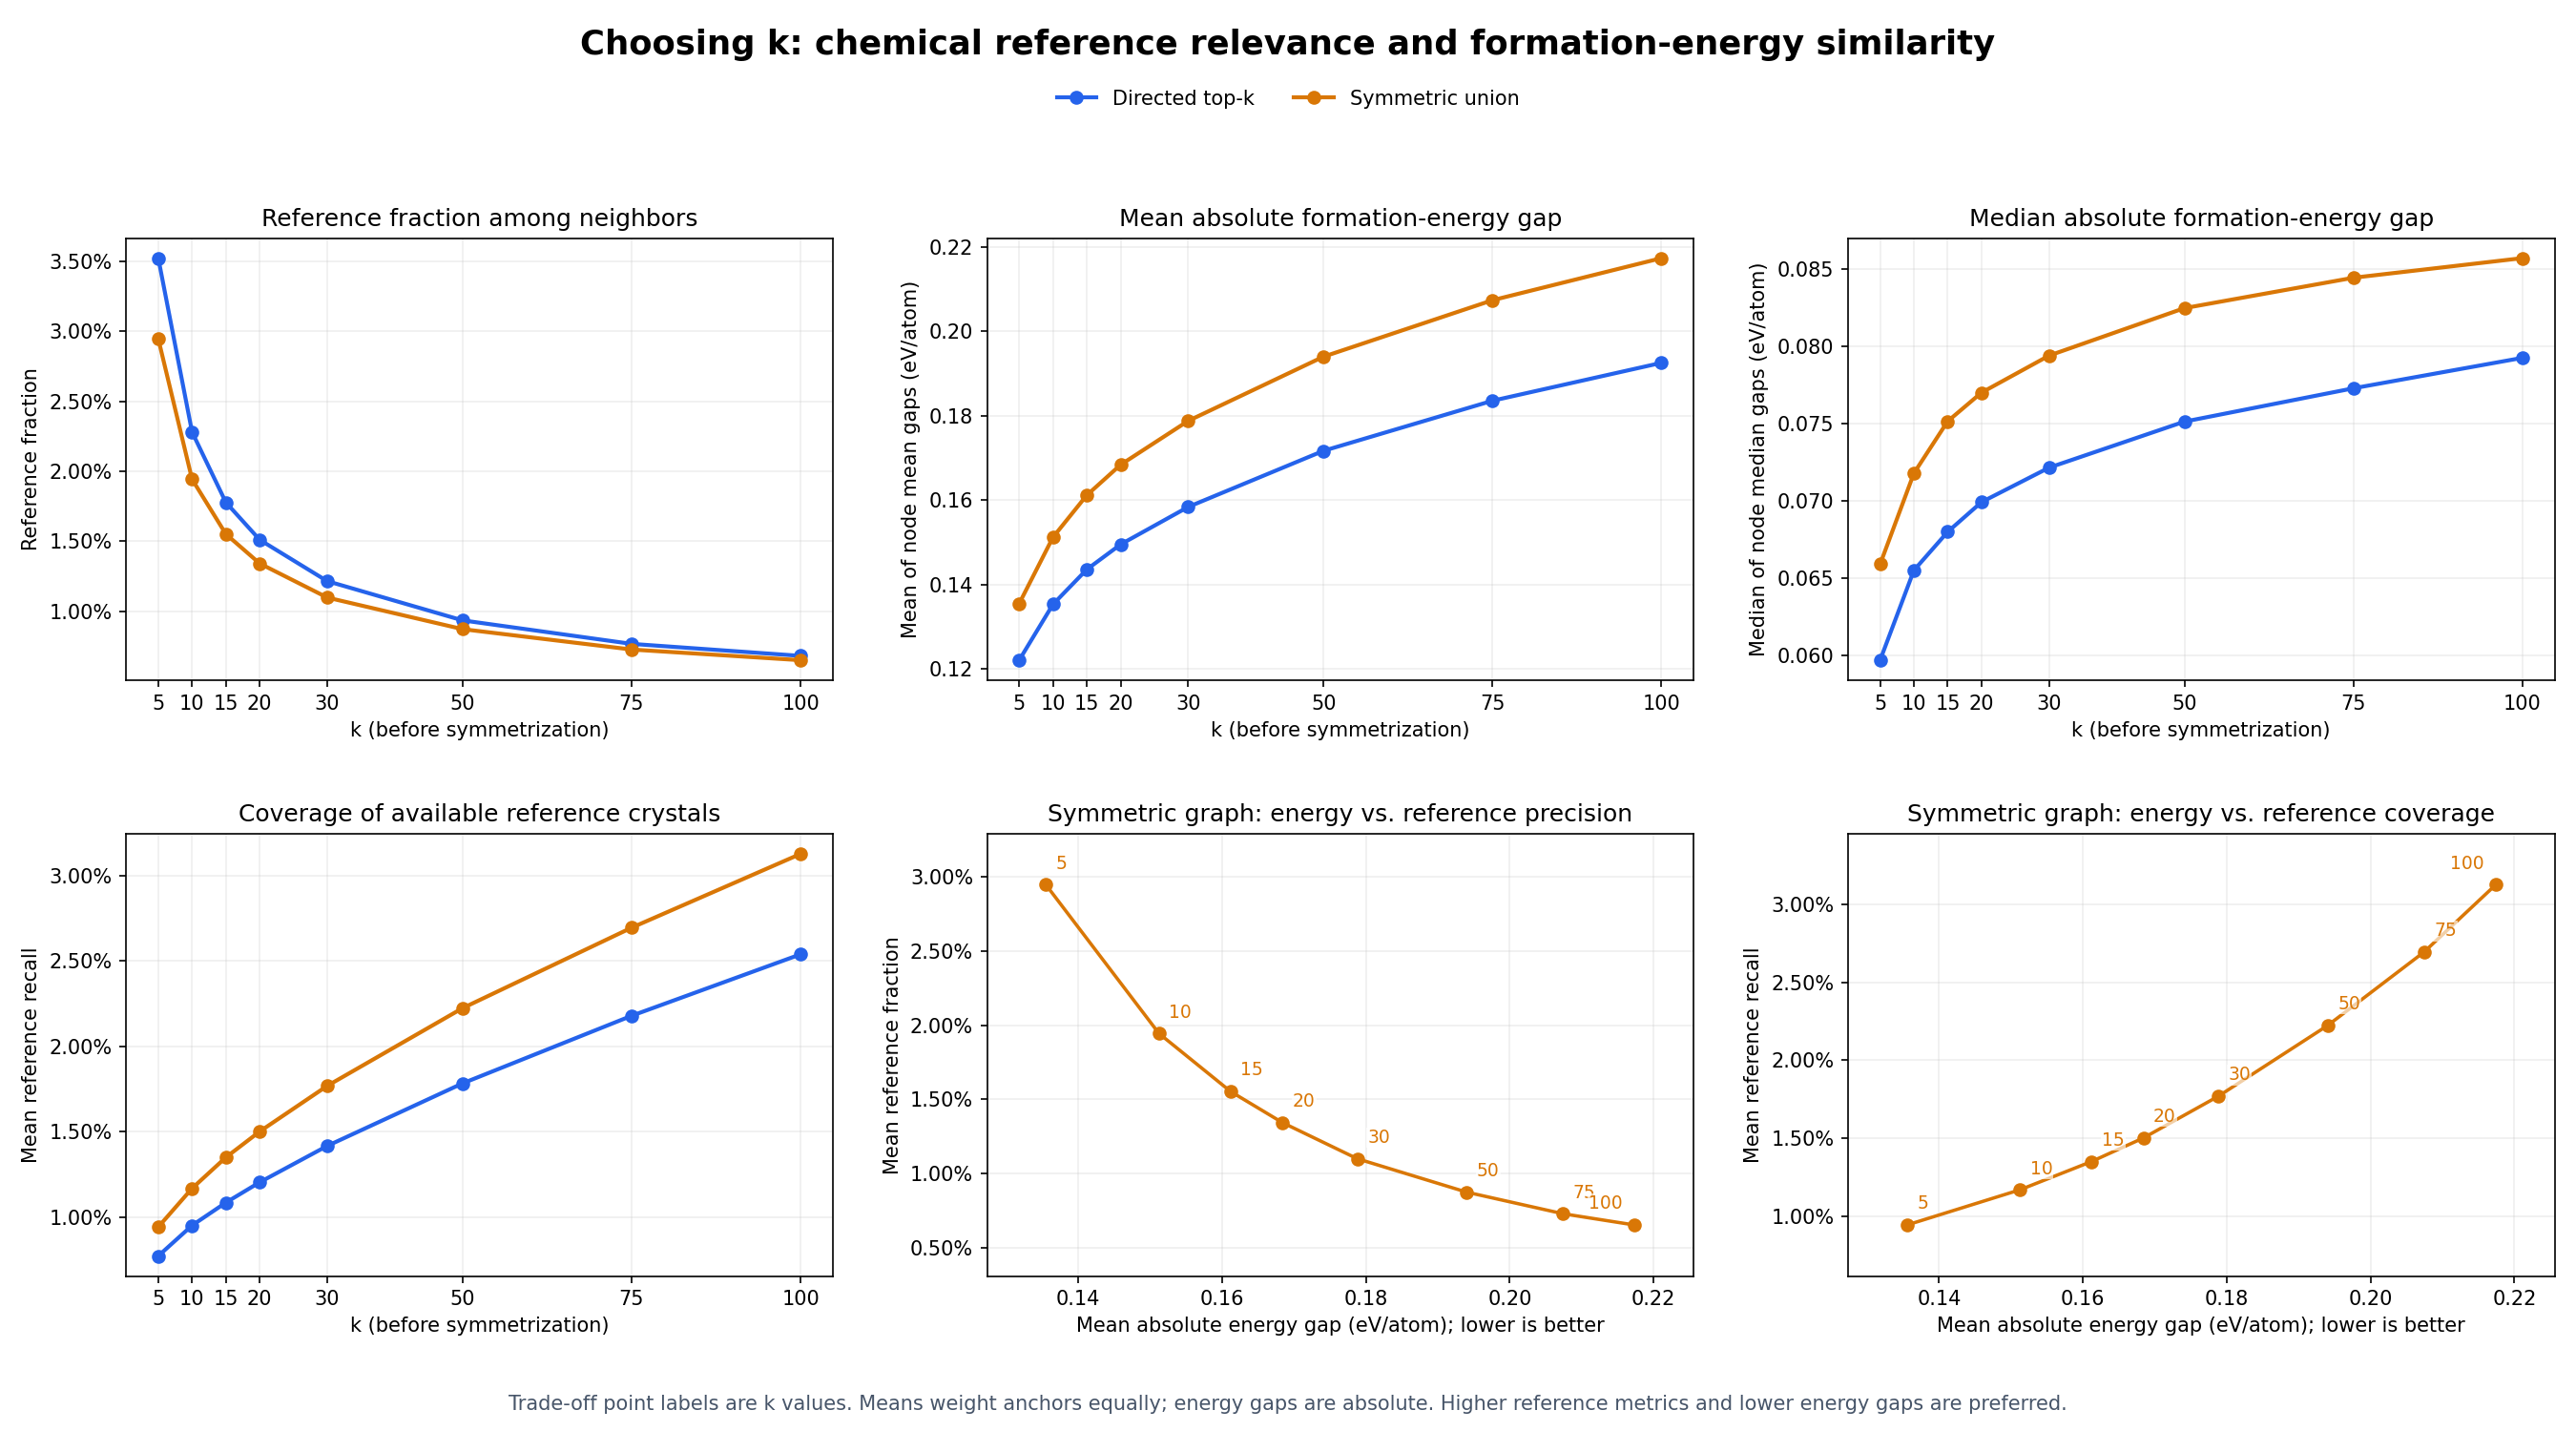

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
colors = {"directed": "#2563eb", "symmetric": "#d97706"}
labels = {"directed": "Directed top-k", "symmetric": "Symmetric union"}
curves = [
    (axes[0, 0], "mean_reference_fraction", "Reference fraction among neighbors", "Reference fraction", True),
    (axes[0, 1], "mean_abs_delta_e", "Mean absolute formation-energy gap", "Mean of node mean gaps (eV/atom)", False),
    (axes[0, 2], "median_node_median_abs_delta_e", "Median absolute formation-energy gap", "Median of node median gaps (eV/atom)", False),
    (axes[1, 0], "mean_reference_recall", "Coverage of available reference crystals", "Mean reference recall", True),
]
for view in ["directed", "symmetric"]:
    values = sweep_summary.loc[view]
    for ax, metric, title, ylabel, is_fraction in curves:
        ax.plot(values.index, values[metric], "o-", color=colors[view], label=labels[view], linewidth=2)
        ax.set(title=title, xlabel="k (before symmetrization)", ylabel=ylabel, xticks=k_values)
        if is_fraction:
            ax.yaxis.set_major_formatter(PercentFormatter(1.0))

    # Focus trade-off point labels on the symmetric graph used downstream.
    if view != "symmetric":
        continue
    for ax, metric, title, ylabel in [
        (axes[1, 1], "mean_reference_fraction", "Symmetric graph: energy vs. reference precision", "Mean reference fraction"),
        (axes[1, 2], "mean_reference_recall", "Symmetric graph: energy vs. reference coverage", "Mean reference recall"),
    ]:
        ax.plot(values["mean_abs_delta_e"], values[metric], "o-", color=colors[view], label=labels[view], linewidth=1.7)
        for candidate_k, row in values.iterrows():
            offset = (-6, 8) if candidate_k == max(k_values) else (5, 8)
            alignment = "right" if candidate_k == max(k_values) else "left"
            ax.annotate(str(candidate_k), (row["mean_abs_delta_e"], row[metric]),
                        xytext=offset, textcoords="offset points", fontsize=9, color=colors[view],
                        ha=alignment, bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.65, "pad": 0.5})
        ax.set(title=title, xlabel="Mean absolute energy gap (eV/atom); lower is better", ylabel=ylabel)
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.margins(x=0.10, y=0.15)

for ax in axes.flat:
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2, frameon=False)
fig.suptitle("Choosing k: chemical reference relevance and formation-energy similarity", fontsize=17, fontweight="bold")
fig.text(0.5, 0.015, "Trade-off point labels are k values. Means weight anchors equally; energy gaps are absolute. Higher reference metrics and lower energy gaps are preferred.",
         ha="center", fontsize=10, color="#475569")
fig.tight_layout(rect=[0, 0.05, 1, 0.91], h_pad=3, w_pad=2.5)
plt.show()

In [18]:
# Dataset-specific interpretation; updates automatically when the sweep is rerun.
symmetric_results = sweep_summary.loc["symmetric"]
connected_options = symmetric_results.index[symmetric_results["connected_components"] == 1]
smallest_k = int(symmetric_results.index.min())
largest_k = int(symmetric_results.index.max())
if len(connected_options):
    connected_k = int(connected_options.min())
    row = symmetric_results.loc[connected_k]
    print(f"If one connected graph is required, start with k={connected_k}, the smallest tested connected configuration.")
    print(f"  Mean reference fraction: {row['mean_reference_fraction']:.2%}")
    print(f"  Mean absolute energy gap: {row['mean_abs_delta_e']:.4f} eV/atom")
    print(f"  Median of node median energy gaps: {row['median_node_median_abs_delta_e']:.4f} eV/atom")
    print(f"  Mean reference recall: {row['mean_reference_recall']:.2%}")
else:
    print("None of the tested k values gives a single connected component.")
print(f"At k={smallest_k}, the graph has {int(symmetric_results.loc[smallest_k, 'connected_components'])} components.")
print(f"At k={largest_k}, mean reference recall reaches {symmetric_results.loc[largest_k, 'mean_reference_recall']:.2%},")
print(f"but mean energy gap is {symmetric_results.loc[largest_k, 'mean_abs_delta_e']:.4f} eV/atom and reference fraction is {symmetric_results.loc[largest_k, 'mean_reference_fraction']:.2%}.")
if (symmetric_results["median_reference_fraction"] == 0).all():
    print("For every tested k, at least half the anchors have no reference neighbor (median reference fraction = 0).")
print("Choose k according to the connectivity/coverage requirement; energy similarity alone does not guarantee chemical reference recovery.")

If one connected graph is required, start with k=10, the smallest tested connected configuration.
  Mean reference fraction: 1.94%
  Mean absolute energy gap: 0.1513 eV/atom
  Median of node median energy gaps: 0.0718 eV/atom
  Mean reference recall: 1.17%
At k=5, the graph has 4 components.
At k=100, mean reference recall reaches 3.13%,
but mean energy gap is 0.2174 eV/atom and reference fraction is 0.65%.
For every tested k, at least half the anchors have no reference neighbor (median reference fraction = 0).
Choose k according to the connectivity/coverage requirement; energy similarity alone does not guarantee chemical reference recovery.


## Reference selection for newly generated crystals

**Comparison with Crys_JEPA:** [`V_screen.py`](../../external/Crys_JEPA/V_screen.py)
identifies a generated crystal's chemical system with `structure.composition.chemical_system`.
[`generate_chemsys_dict`](../../external/Crys_JEPA/eval/vsun/reference/utils.py) makes its
key by sorting the **unique element symbols**. Both screening and evaluation enumerate
`combinations(elements, r)` for every `r = 1, ..., n_elements`, including the full system.
Our existing combination technique therefore matches the upstream rule.

Chemical identity comes from the structure or metadata, independently of the embedding.
The functions below accept a metadata row with `chemical_system` and/or `elements`, a
chemical-system string such as `Li-O`, or a pymatgen Structure. Element-list strings from
CSV are parsed safely. Stoichiometry is not used; a formula such as `Li2O` should be supplied
via structure/metadata, not passed as a chemical-system string.

Two selectors use the **existing** metadata/embedding pool:
1. `get_reference_set_for_new_crystal(query_metadata)` selects the original chemical references.
2. `get_augmented_reference_set(query_embedding, query_metadata, k=10)` returns the union of
   those references and the query's k nearest existing embeddings, without duplicates.

The top-k is selected from the whole existing pool and can overlap chemical references;
it does not mean k *additional* non-reference rows. New crystals are not automatically
inserted into the pool. New-to-existing distances must be computed for each new query;
the earlier existing-to-existing neighbor cache does not contain these queries.
Use the same encoder, input scaler, and embedding preprocessing for both files. Any
centering uses the **existing pool's mean for both query and pool**, preserving distances.

New crystals have no self row to remove by default. For experiments querying a crystal
already in the pool, pass `exclude_reference_index=` explicitly. IDs alone do not trigger
exclusion because generated datasets may reuse IDs. Returned `embedding_index` values
always identify positional rows of the existing embedding array.

The augmented set is an embedding-screening experiment and can include other chemical
systems. Convex-hull evaluation should retain its chemically admissible reference rule.

In [19]:
import ast
from collections.abc import Mapping
from itertools import combinations
from numbers import Integral

from sklearn.metrics import pairwise_distances

_ELEMENT_SYMBOLS = set((
    "H He Li Be B C N O F Ne Na Mg Al Si P S Cl Ar K Ca Sc Ti V Cr Mn Fe Co Ni Cu Zn "
    "Ga Ge As Se Br Kr Rb Sr Y Zr Nb Mo Tc Ru Rh Pd Ag Cd In Sn Sb Te I Xe Cs Ba La Ce "
    "Pr Nd Pm Sm Eu Gd Tb Dy Ho Er Tm Yb Lu Hf Ta W Re Os Ir Pt Au Hg Tl Pb Bi Po At Rn "
    "Fr Ra Ac Th Pa U Np Pu Am Cm Bk Cf Es Fm Md No Lr Rf Db Sg Bh Hs Mt Ds Rg Cn Nh Fl Mc Lv Ts Og"
).split())


def _canonical_element_key(elements):
    if not isinstance(elements, (list, tuple, set, frozenset, np.ndarray)) or len(elements) == 0:
        raise ValueError("Supply a non-empty collection of element symbols.")
    symbols = [element.strip() if isinstance(element, str) else getattr(element, "symbol", None)
               for element in elements]
    if any(symbol not in _ELEMENT_SYMBOLS for symbol in symbols):
        raise ValueError(f"Invalid element symbols: {symbols!r}")
    return "-".join(sorted(set(symbols)))


def identify_chemical_system(crystal):
    """Canonical sorted unique element key, matching the upstream chemical-system rule.

    Accepts a chemical-system string, metadata mapping/Series, or pymatgen Structure.
    An embedding alone cannot specify a chemical system. If both metadata fields
    'chemical_system' and 'elements' are supplied, they must agree.
    """
    if hasattr(crystal, "composition") and hasattr(crystal.composition, "chemical_system"):
        return identify_chemical_system(crystal.composition.chemical_system)
    if isinstance(crystal, str):
        return _canonical_element_key(crystal.split("-"))
    if not isinstance(crystal, (Mapping, pd.Series)):
        raise TypeError("Supply chemical-system metadata, a system string, or a Structure.")

    def present(value):
        return value is not None and value is not pd.NA and not (
            isinstance(value, (float, np.floating)) and np.isnan(value)
        )

    system = crystal.get("chemical_system")
    elements = crystal.get("elements")
    keys = []
    if present(system):
        keys.append(identify_chemical_system(system))
    if present(elements):
        if isinstance(elements, str):
            try:
                elements = ast.literal_eval(elements)
            except (ValueError, SyntaxError) as error:
                raise ValueError("elements must be a list of symbols or its CSV list representation.") from error
        keys.append(_canonical_element_key(elements))
    if not keys:
        raise ValueError("The query needs chemical_system or elements metadata (or a Structure).")
    if len(set(keys)) != 1:
        raise ValueError("chemical_system and elements describe different element sets.")
    return keys[0]


def _pool_chemical_systems(reference_metadata):
    if not isinstance(reference_metadata, pd.DataFrame):
        raise TypeError("reference_metadata must be a DataFrame aligned with reference_embeddings.")
    if "chemical_system" in reference_metadata:
        return reference_metadata["chemical_system"].map(identify_chemical_system)
    if "elements" in reference_metadata:
        return reference_metadata["elements"].map(lambda elements: identify_chemical_system({"elements": elements}))
    raise ValueError("Reference metadata needs chemical_system or elements.")


def _validate_reference_exclusion(position, n_rows):
    if position is None:
        return None
    if isinstance(position, (bool, np.bool_)) or not isinstance(position, Integral):
        raise TypeError("exclude_reference_index must be an integer row position or None.")
    if not 0 <= position < n_rows:
        raise IndexError("exclude_reference_index is outside the existing reference pool.")
    return int(position)


def get_reference_set_for_new_crystal(query_metadata, *, reference_metadata=None,
                                      exclude_reference_index=None):
    """Select all existing crystals in the query's system or non-empty subsystems.

    Defaults to the notebook's loaded metadata pool. The query may be a metadata row,
    chemical-system string, or Structure. Returns metadata indexed by embedding position.
    No formation energy, embedding, or existing material ID is needed for this rule.
    """
    pool = metadata if reference_metadata is None else reference_metadata
    systems = _pool_chemical_systems(pool)
    query_system = identify_chemical_system(query_metadata)
    elements = query_system.split("-")
    allowed_systems = {
        "-".join(subsystem)
        for size in range(1, len(elements) + 1)
        for subsystem in combinations(elements, size)
    }
    positions = np.flatnonzero(systems.isin(allowed_systems).to_numpy())
    excluded = _validate_reference_exclusion(exclude_reference_index, len(pool))
    if excluded is not None:
        positions = positions[positions != excluded]
    result = pool.iloc[positions].copy()
    result.index = pd.Index(positions, name="embedding_index")
    result.attrs["query_chemical_system"] = query_system
    return result


def get_augmented_reference_set(query_embedding, query_metadata, k=10, *,
                                 reference_embeddings=None, reference_metadata=None,
                                 exclude_reference_index=None):
    """Return chemical references UNION top-k nearest existing crystals.

    Searches exact Euclidean distances in the existing pool only; k counts all nearest
    neighbors, including any overlap with chemical references. Duplicate positions are
    returned once. Rows are sorted by distance, breaking ties by embedding row position.
    Added columns: euclidean_distance, in_chemical_reference_set, in_knn, knn_rank
    (1-based, nullable), and reference_source ('chemical_only', 'knn_only', 'both').
    """
    pool = metadata if reference_metadata is None else reference_metadata
    X = np.asarray(embeddings if reference_embeddings is None else reference_embeddings)
    if not isinstance(pool, pd.DataFrame):
        raise TypeError("reference_metadata must be a DataFrame.")
    if X.ndim != 2 or len(X) != len(pool) or len(X) == 0 or X.shape[1] == 0:
        raise ValueError("reference_embeddings must be non-empty 2D data aligned with reference_metadata.")
    if X.dtype.kind not in "iuf" or not np.isfinite(X).all():
        raise ValueError("Reference embeddings must contain finite real numeric values.")
    query = np.asarray(query_embedding)
    if query.ndim == 2 and query.shape[0] == 1:
        query = query[0]
    if query.shape != (X.shape[1],) or query.dtype.kind not in "iuf" or not np.isfinite(query).all():
        raise ValueError(f"query_embedding must be a finite vector of length {X.shape[1]}.")
    excluded = _validate_reference_exclusion(exclude_reference_index, len(pool))
    available = len(pool) - int(excluded is not None)
    if isinstance(k, (bool, np.bool_)) or not isinstance(k, Integral) or not 1 <= k <= available:
        raise ValueError(f"k must be an integer between 1 and {available}.")

    chemical = get_reference_set_for_new_crystal(
        query_metadata, reference_metadata=pool, exclude_reference_index=excluded,
    )
    # Fit the center on the existing pool; never center a generated file independently.
    centered = X.astype(np.float64, copy=True)
    pool_mean = centered.mean(axis=0, keepdims=True)
    centered -= pool_mean
    centered_query = query.astype(np.float64, copy=True).reshape(1, -1) - pool_mean
    distances = pairwise_distances(centered_query, centered, metric="euclidean")[0]
    if excluded is not None:
        distances[excluded] = np.inf
    nearest = np.argsort(distances, kind="stable")[:k]
    chemical_positions = chemical.index.to_numpy(dtype=np.intp)
    union = np.union1d(chemical_positions, nearest)
    positions = union[np.lexsort((union, distances[union]))]

    result = pool.iloc[positions].copy()
    result.index = pd.Index(positions, name="embedding_index")
    result["euclidean_distance"] = distances[positions]
    result["in_chemical_reference_set"] = np.isin(positions, chemical_positions)
    result["in_knn"] = np.isin(positions, nearest)
    rank_by_position = {int(position): rank for rank, position in enumerate(nearest, start=1)}
    result["knn_rank"] = pd.array([rank_by_position.get(int(position), pd.NA) for position in positions], dtype="Int64")
    result["reference_source"] = np.where(
        result["in_chemical_reference_set"],
        np.where(result["in_knn"], "both", "chemical_only"), "knn_only",
    )
    overlap = int(result["in_chemical_reference_set"].mul(result["in_knn"]).sum())
    result.attrs.update({
        "query_chemical_system": chemical.attrs["query_chemical_system"], "k": int(k),
        "chemical_reference_count": len(chemical), "knn_count": len(nearest),
        "overlap_count": overlap, "added_knn_count": int(k) - overlap,
        "augmented_reference_count": len(result),
    })
    return result

In [20]:
# Execute only the two pure subsystem helpers, not the GPU screening scripts.
_upstream_paths = [
    parent / "external" / "Crys_JEPA"
    for parent in (Path.cwd(), *Path.cwd().parents)
]
upstream_repo = next((folder for folder in _upstream_paths if (folder / "V_screen.py").is_file()), None)
if upstream_repo is None:
    raise FileNotFoundError("The external/Crys_JEPA clone is needed for this comparison cell.")
upstream_expanders = []
for relative in ["V_screen.py", "eval/vsun/reference/utils.py"]:
    tree = ast.parse((upstream_repo / relative).read_text(encoding="utf-8"))
    function = next(node for node in tree.body
                    if isinstance(node, ast.FunctionDef) and node.name == "expand_into_subsystems")
    scope = {"combinations": combinations}
    exec(compile(ast.Module(body=[function], type_ignores=[]), str(upstream_repo / relative), "exec"), scope)
    upstream_expanders.append(scope["expand_into_subsystems"])

pool_systems = _pool_chemical_systems(metadata)
groups = pool_systems.groupby(pool_systems, sort=False).indices
for system in groups:
    elements = system.split("-")
    our_keys = {"-".join(subsystem) for size in range(1, len(elements) + 1)
                for subsystem in combinations(elements, size)}
    for expand in upstream_expanders:
        upstream_keys = {"-".join(sorted(subsystem)) for subsystem in expand(system)}
        if our_keys != upstream_keys:
            raise AssertionError(f"Subsystem mismatch for {system}")
    expected_positions = np.sort(np.concatenate([groups[key] for key in our_keys if key in groups]))
    np.testing.assert_array_equal(_reference_positions(system), expected_positions)
print(f"Matched both upstream subsystem helpers and our existing reference cache for all {len(groups):,} chemical systems.")
print("Canonical element key example:", identify_chemical_system({"chemical_system": "O-Li-Li", "elements": "['Li', 'O']"}))

Matched both upstream subsystem helpers and our existing reference cache for all 16,549 chemical systems.
Canonical element key example: Li-O


In [21]:
# Demonstration only: use an existing row as a held-out stand-in for a future new crystal.
# This is not a newly generated sample. Exclude its known existing row in both selectors.
demo_query_index = 0
demo_query_metadata = metadata.iloc[demo_query_index]
demo_query_embedding = embeddings[demo_query_index]
chemical_references_demo = get_reference_set_for_new_crystal(
    demo_query_metadata, exclude_reference_index=demo_query_index,
)
augmented_references_demo = get_augmented_reference_set(
    demo_query_embedding, demo_query_metadata, k=10,
    exclude_reference_index=demo_query_index,
)
print(f"Held-out demonstration: {demo_query_metadata['material_id']} ({identify_chemical_system(demo_query_metadata)})")
display(pd.Series(augmented_references_demo.attrs, name="value").to_frame())
print("First 15 rows of the augmented set, sorted by distance to the query:")
display(augmented_references_demo.head(15))
print("Newly added neighbors from outside the original chemical reference set:")
display(augmented_references_demo.loc[augmented_references_demo["reference_source"] == "knn_only"])

Held-out demonstration: mp-1221227 (Co-Mn-Na-Ni-O)


,value
query_chemical_system,Co-Mn-Na-Ni-O
k,10
chemical_reference_count,118
knn_count,10
overlap_count,0
added_knn_count,10
augmented_reference_count,128


First 15 rows of the augmented set, sorted by distance to the query:


,material_id,formation_energy_per_atom,band_gap,pretty_formula,e_above_hull,elements,spacegroup.number,num_id,chemical_system,euclidean_distance,in_chemical_reference_set,in_knn,knn_rank,reference_source
embedding_index,,,,,,,,,,,,,,
3507,mp-756860,-1.651299,0.2438,LiMn5(CuO6)2,0.076808,"['Cu', 'Li', 'Mn', 'O']",5,3507,Cu-Li-Mn-O,0.295407,False,True,1,knn_only
13214,mp-1273581,-1.604426,0.0000,Li3Fe3O8,0.068982,"['Fe', 'Li', 'O']",12,13214,Fe-Li-O,0.308589,False,True,2,knn_only
5098,mp-8300,-1.579251,0.7184,Ba4As2O,0.000000,"['Ba', 'As', 'O']",139,5098,As-Ba-O,0.320457,False,True,3,knn_only
14527,mp-18781,-1.637491,2.3400,CrCdO4,0.000000,"['Cd', 'Cr', 'O']",63,14527,Cd-Cr-O,0.363400,False,True,4,knn_only
1150,mp-841,-1.650170,2.0228,Li2O2,0.000000,"['Li', 'O']",194,1150,Li-O,0.371897,False,True,5,knn_only
6310,mp-30988,-1.727406,2.0739,KBiO2,0.000000,"['Bi', 'K', 'O']",15,6310,Bi-K-O,0.394595,False,True,6,knn_only
14665,mp-9615,-1.674924,0.0000,LiTiS2,0.000000,"['Li', 'Ti', 'S']",164,14665,Li-S-Ti,0.396048,False,True,7,knn_only
5131,mp-621024,-1.593297,0.0000,Gd6C3Cl5,0.007616,"['C', 'Cl', 'Gd']",12,5131,C-Cl-Gd,0.408307,False,True,8,knn_only
9749,mp-15885,-1.645073,0.0000,Li2US3,0.000000,"['Li', 'U', 'S']",12,9749,Li-S-U,0.426575,False,True,9,knn_only


Newly added neighbors from outside the original chemical reference set:


,material_id,formation_energy_per_atom,band_gap,pretty_formula,e_above_hull,elements,spacegroup.number,num_id,chemical_system,euclidean_distance,in_chemical_reference_set,in_knn,knn_rank,reference_source
embedding_index,,,,,,,,,,,,,,
3507,mp-756860,-1.651299,0.2438,LiMn5(CuO6)2,0.076808,"['Cu', 'Li', 'Mn', 'O']",5,3507,Cu-Li-Mn-O,0.295407,False,True,1,knn_only
13214,mp-1273581,-1.604426,0.0000,Li3Fe3O8,0.068982,"['Fe', 'Li', 'O']",12,13214,Fe-Li-O,0.308589,False,True,2,knn_only
5098,mp-8300,-1.579251,0.7184,Ba4As2O,0.000000,"['Ba', 'As', 'O']",139,5098,As-Ba-O,0.320457,False,True,3,knn_only
14527,mp-18781,-1.637491,2.3400,CrCdO4,0.000000,"['Cd', 'Cr', 'O']",63,14527,Cd-Cr-O,0.363400,False,True,4,knn_only
1150,mp-841,-1.650170,2.0228,Li2O2,0.000000,"['Li', 'O']",194,1150,Li-O,0.371897,False,True,5,knn_only
6310,mp-30988,-1.727406,2.0739,KBiO2,0.000000,"['Bi', 'K', 'O']",15,6310,Bi-K-O,0.394595,False,True,6,knn_only
14665,mp-9615,-1.674924,0.0000,LiTiS2,0.000000,"['Li', 'Ti', 'S']",164,14665,Li-S-Ti,0.396048,False,True,7,knn_only
5131,mp-621024,-1.593297,0.0000,Gd6C3Cl5,0.007616,"['C', 'Cl', 'Gd']",12,5131,C-Cl-Gd,0.408307,False,True,8,knn_only
9749,mp-15885,-1.645073,0.0000,Li2US3,0.000000,"['Li', 'U', 'S']",12,9749,Li-S-U,0.426575,False,True,9,knn_only


### Connect the future generated-crystal files

Set the paths below to your generated embedding and metadata files. Rows must align,
and embeddings must use the same 512-dimensional representation as the existing pool.
A query needs chemical-system metadata; formation energy is not required for either selector.
The example evaluates the first generated crystal, searching only the existing pool.

In [22]:
generated_embeddings_path = data_dir / "generated" / "embeddings.npy"
generated_metadata_path = data_dir / "generated" / "metadata.csv"

if generated_embeddings_path.is_file() and generated_metadata_path.is_file():
    generated_embeddings = np.load(generated_embeddings_path, allow_pickle=False)
    generated_metadata = pd.read_csv(generated_metadata_path)
    if generated_embeddings.ndim != 2 or generated_embeddings.shape[1] != embeddings.shape[1]:
        raise ValueError("Generated embedding feature dimensions must match the existing pool.")
    if len(generated_embeddings) != len(generated_metadata) or len(generated_metadata) == 0:
        raise ValueError("Generated embeddings and metadata need matching nonzero row counts.")
    generated_query_index = 0
    generated_query_metadata = generated_metadata.iloc[generated_query_index]
    original_generated_references = get_reference_set_for_new_crystal(generated_query_metadata)
    augmented_generated_references = get_augmented_reference_set(
        generated_embeddings[generated_query_index], generated_query_metadata, k=10,
    )
    print("Generated query:", generated_query_metadata.get("material_id", generated_query_index))
    display(pd.Series(augmented_generated_references.attrs, name="value").to_frame())
    display(augmented_generated_references.head(15))
elif generated_embeddings_path.exists() or generated_metadata_path.exists():
    raise FileNotFoundError("Both generated embeddings.npy and metadata.csv are required at the configured paths.")
else:
    print("Generated files are not present yet; both selection functions are ready.")
    print("Set generated_embeddings_path and generated_metadata_path above, then rerun this cell.")

Generated files are not present yet; both selection functions are ready.
Set generated_embeddings_path and generated_metadata_path above, then rerun this cell.
